# 04 搜索对照、消融与历史证据

本节属于课程进阶模块。代码、教学构造、历史实测、待执行实验分别标注。云执行默认关闭；真实金融数据通过仓库外的私有快照接入。原始行情、逐样本标签、角度、核矩阵、参数与预测不得存入公开Notebook输出。

**来源**：[L001 ICLR正式版](https://proceedings.iclr.cc/paper_files/paper/2024/file/4d9944ab3330fe6af8efb9260aa9f307-Paper-Conference.pdf)、[本课程协议](../../docs/天衍云端复现协议.md)。署名：Julius Zhou、AUFE、Cong Lei。代码MIT，原创教学文字与图表CC BY 4.0。


In [1]:
from pathlib import Path
import sys, os, json
import numpy as np
import pandas as pd
COURSE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "课程大纲.md").exists())
MODULE = COURSE / "experiments/qukernet_finance"
sys.path.insert(0, str(MODULE))
PUBLIC = COURSE / "reports/qukernet_cloud_v2"
ENABLE_CLOUD = False
print("默认云执行关闭；当前Notebook不读取凭据、不提交任务。")


默认云执行关闭；当前Notebook不读取凭据、不提交任务。


## 同配额不等于同耗时
随机搜索应匹配完整核对齐评价与微调配额；还要分别报告实际耗时。背景基线不能代替HEAK/TEK。TEK的可训练参数和广义移位调用要单独计费，不能套用QuKerNet缩规模参数上限。

本节读取**2026-11-09无影CPU历史汇总**，新云主实验仍未运行。输入为已授权公开的汇总CSV，输出为对照图；不读取逐样本金融数据。

In [2]:
history=pd.read_csv(PUBLIC/"historical_search_aggregates.csv")
classification=history[(history.task=="classification") & (history.method=="qukernet")]
display(classification[["stage","alignment","validation_accuracy","test_accuracy","execution_location"]])

,stage,alignment,validation_accuracy,test_accuracy,execution_location
36,pre,0.122853,0.575,0.422727,historical_wuying_cpu
37,post,0.123966,0.625,0.413636,historical_wuying_cpu


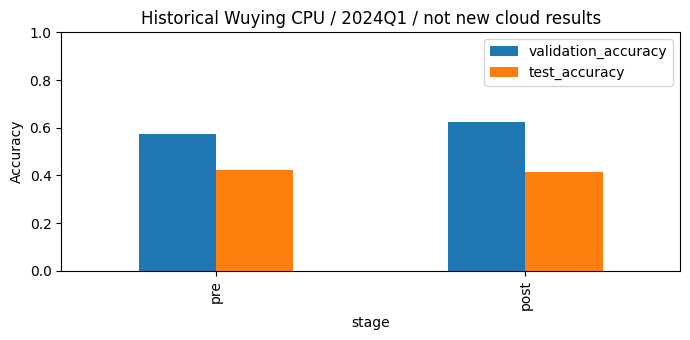

In [3]:
import matplotlib.pyplot as plt
ax=classification.set_index("stage")[["validation_accuracy","test_accuracy"]].plot.bar(figsize=(7,3.5),ylim=(0,1))
ax.set_title("Historical Wuying CPU / 2024Q1 / not new cloud results")
ax.set_ylabel("Accuracy")
plt.tight_layout();plt.show()

## 解释而不追逐最高分
旧结果中KTA略增，验证准确率改善，后续季度准确率反而下降。它说明代理、选择与后续评价存在区别，不证明方法必然无效。新实验须控制市场窗口与模型种子，补多数类、RBF等基线，并报告类比例。

消融登记覆盖特征数8/16/24/32/40/80、mRMR对随机特征、top-k5/10、配置0/5/10/20、NKN与BO。当前登记不等于已实现且跑通所有比较；模块状态表须逐项阅读。

**验收与作业**：设计能分别识别神经筛选贡献和微调贡献的对照；给出为什么同样50,000候选不等于相同量子计算预算。不得将开发期季度评价重新命名为封存测试。